# T01 — Your first grounding impedance

In this tutorial you compute the grounding impedance of a single driven
rod in homogeneous soil, read the result in the three ways
`groundfield` offers, and check the number against two independent
references: Dwight's closed-form formula (1936) and the analytic
potential of a line source. At the end you repeat the exercise for a
buried ring.

**You will learn**

- the five steps of every `groundfield` computation: soil, world,
  electrode, source, engine;
- how to read impedances, potentials and currents from a
  `FieldResult`;
- how to evaluate the potential anywhere in the soil or on the surface;
- how to convince yourself that a number is right.

**Prerequisites:** `pip install groundfield`. Runtime: a few seconds.

## What we compute and why

A grounding system (earth electrode) leads current into the soil. If a
current $I_E$ flows into the electrode, its potential rises against
remote earth by the earth potential rise $U_E$. The ratio is the
**grounding impedance**

$$
Z_E = \frac{U_E}{I_E}.
$$

Below about 1 kHz the soil behaves like a resistive conductor: the
displacement current is negligible and the potential $\varphi$ obeys
the stationary current-flow equation
$\nabla \cdot (\sigma \nabla \varphi) = 0$ outside the electrode, with
$\sigma = 1/\rho$. For homogeneous soil the solution is built from the
Green's function of a point current source $I$ at depth $z'$ in a
half-space,

$$
\varphi(\mathbf r) = \frac{\rho I}{4\pi}
  \left(\frac{1}{|\mathbf r - \mathbf r'|}
      + \frac{1}{|\mathbf r - \mathbf r'_\mathrm{img}|}\right),
$$

where the image source $\mathbf r'_\mathrm{img}$ above the surface makes
the surface insulating (no current flows into the air). `groundfield`
splits the electrode into short segments, places line sources on them
and determines their currents so that the electrode is an
equipotential body. A single electrode without inductive conductors
gives a real impedance — a grounding *resistance*.

Conventions used throughout: SI units, depth $z$ positive **downwards**
(the soil surface is $z = 0$), phasors $\underline{x}(t) =
\mathrm{Re}\{X e^{j\omega t}\}$ with RMS amplitudes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf
from groundfield.references import dwight1936

print("groundfield", gf.__version__)

groundfield 2026.11.0


## Step 1–3: soil, world, electrode and source

The soil is homogeneous with $\rho = 100\ \Omega\,\mathrm m$. A
**world** holds the soil model together with every electrode,
conductor and source. The rod starts at the surface (its head at
$z = 0$) and reaches 3 m deep; the wire radius is 8 mm, a common
driven rod. The source feeds 1 A into the rod and the current returns
through remote earth, so the potential of the rod in volts *is* the
impedance in ohms.

In [2]:
RHO = 100.0  # soil resistivity in Ohm m
L_ROD = 3.0  # rod length in m
A_ROD = 0.008  # wire radius in m

world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO), name="T01 rod")
gf.create_electrode(
    world,
    "rod",
    name="rod",
    position=(0.0, 0.0, 0.0),  # head of the rod (x, y, z), z down
    length=L_ROD,
    wire_radius=A_ROD,
)
gf.create_source(world, attached_to="rod", magnitude=1.0)  # 1 A
print(world.soil)
print(world.electrodes[0])
print(world.sources[0])

kind='homogeneous' rho=100.0 relative_permittivity=10.0
name='rod' kind='rod' wire_radius=0.008 position=(0.0, 0.0, 0.0) length=3.0 concrete_shell_coefficient_ohm_m=0.0
name='source_0' kind='current' attached_to='rod' return_to=None magnitude=1.0 phase_deg=0.0


## Step 4–5: engine and solve

The **engine** chooses the numerical method (the *backend*), the
frequencies and the discretisation. `image` is the image method for
homogeneous soil; for layered soil it forwards to the matching layered
backend automatically. `segment_length` is the length of the wire
segments in metres. The engine solves the world and returns a
`FieldResult`.

In [3]:
engine = gf.create_engine(backend="image", segment_length=0.5, frequencies=[50.0])
result = engine.solve(world)
print(result.summary())
print("kernel used:", result.metadata["kernel"])

FieldResult(backend='image', n_freq=1, n_electrodes=1, n_segments=6)
kernel used: line


## Reading the result

Three accessors answer the question "what is the impedance?":

- `input_impedance()` — the **driving-point impedance** the source
  sees: potential of the fed node minus potential of the return node,
  divided by the source current. This is what an earth tester or a
  fault sees.
- `cluster_impedance(name)` — potential of the galvanic cluster
  (electrodes bonded together) divided by the current that this
  cluster leaks into the soil.
- `electrode_potentials` / `electrode_currents` — the raw potential and
  leakage current per electrode and frequency.

For a single electrode fed from remote earth all three agree.
Tutorial [T03](T03_interconnected_systems_and_impedances.ipynb) shows
when and why they differ. Each accessor returns one value per
frequency.

In [4]:
z_in = result.input_impedance()[0]
z_cluster = result.cluster_impedance("rod")[0]
u_rod = result.electrode_potentials["rod"][0]
i_rod = result.electrode_currents["rod"][0]

print(f"input impedance   Z_in      = {z_in:.4f} Ohm")
print(f"cluster impedance Z_cluster = {z_cluster:.4f} Ohm")
print(f"U_E = {u_rod:.4f} V at I_E = {i_rod:.4f} A")
result.to_dataframe()

input impedance   Z_in      = 33.4997+0.0000j Ohm
cluster impedance Z_cluster = 33.4997+0.0000j Ohm
U_E = 33.4997+0.0000j V at I_E = 1.0000+0.0000j A


,frequency_hz,electrode,cluster,potential_v,current_a,cluster_impedance_ohm
0,50.0,rod,rod,33.499733+ 0.000000j,1.0+0.0j,33.499733+ 0.000000j


In [5]:
assert abs(z_in - z_cluster) < 1e-12 * abs(z_in)
assert abs(z_in.imag) < 1e-12  # no inductive conductor: a resistance
assert abs(i_rod - 1.0) < 1e-12  # the whole current leaves the rod

## Cross-check 1: Dwight's formula

Dwight (1936) gives the resistance of a rod of length $L$ and radius
$a$ that starts at the surface of homogeneous soil:

$$
R = \frac{\rho}{2\pi L}\left(\ln\frac{4L}{a} - 1\right),
\qquad a \ll L .
$$

`groundfield.references.dwight1936` implements this and other closed
forms of Dwight's Table I.

In [6]:
r_dwight = dwight1936.rod(RHO, L_ROD, A_ROD)
deviation = z_in.real / r_dwight - 1.0
print(f"groundfield: {z_in.real:.4f} Ohm")
print(f"Dwight 1936: {r_dwight:.4f} Ohm")
print(f"deviation:   {deviation:+.3%}")

groundfield: 33.4997 Ohm
Dwight 1936: 33.4927 Ohm
deviation:   +0.021%


In [7]:
assert abs(deviation) < 1e-3  # Dwight quotes < 1 % for the rod formula

The two numbers agree to a small fraction of a percent. Dwight's
formula neglects terms of order $a/L$; `groundfield` evaluates the
exact potential of a uniformly leaking line current, which is the
same physical model without that approximation.

## Cross-check 2: the potential on the surface

`result.potential(points)` evaluates the potential at arbitrary points
(an array of shape `(M, 3)`, coordinates in metres) for one frequency.
Along the surface ($z = 0$) the potential falls from $U_E$ towards
remote earth — the classical *potential funnel* around a rod.

For a rod that leaks a uniform current $I$ over its length $L$, the
surface potential at horizontal distance $r$ follows from integrating
the point-source Green's function above over the rod (source and image
coincide on the surface):

$$
\varphi(r, z = 0) = \frac{\rho I}{2\pi L}\,
  \operatorname{arsinh}\frac{L}{r}.
$$

The image backend uses exactly this current distribution (one uniform
current along each straight wire, here the rod), so the two curves must coincide; the cell
prints the largest relative difference along the surface.

largest relative difference along the surface: 4.2e-05
potential 1 m from the rod: 9.65 V of U_E = 33.50 V


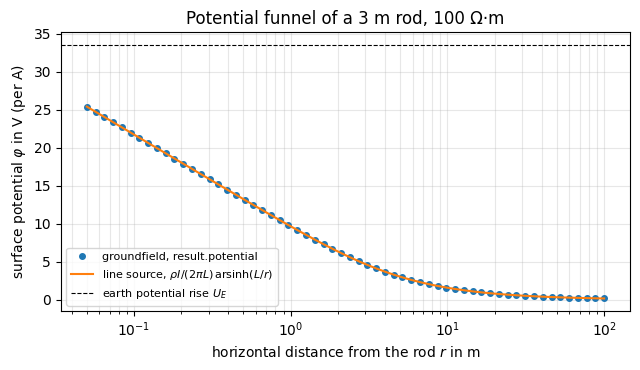

In [8]:
r = np.geomspace(0.05, 100.0, 60)  # horizontal distance in m
surface = np.column_stack([r, np.zeros_like(r), np.zeros_like(r)])
phi = result.potential(surface).real  # V, for the 1 A source
phi_analytic = RHO * 1.0 / (2.0 * np.pi * L_ROD) * np.arcsinh(L_ROD / r)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(r, phi, "o", ms=4, label="groundfield, result.potential")
ax.semilogx(
    r, phi_analytic, "-", label=r"line source, $\rho I/(2\pi L)\,$arsinh$(L/r)$"
)
ax.axhline(u_rod.real, color="k", ls="--", lw=0.8, label="earth potential rise $U_E$")
ax.set_xlabel("horizontal distance from the rod $r$ in m")
ax.set_ylabel(r"surface potential $\varphi$ in V (per A)")
ax.set_title("Potential funnel of a 3 m rod, 100 Ω·m")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

worst = np.max(np.abs(phi / phi_analytic - 1.0))
phi_1m = result.potential(np.array([[1.0, 0.0, 0.0]]))[0].real
print(f"largest relative difference along the surface: {worst:.1e}")
print(f"potential 1 m from the rod: {phi_1m:.2f} V of U_E = {u_rod.real:.2f} V")

In [9]:
assert worst < 1e-4
assert phi_1m < 0.5 * u_rod.real

Half of the earth potential rise is lost within about one metre of the
rod: a person standing 1 m away and touching the rod bridges that
difference (the *touch voltage*, tutorial
[T08](T08_touch_and_step_assessment.ipynb)).

## A second electrode: the buried ring

A horizontal ring of radius 5 m buried at 0.6 m is a typical
station earth electrode. Dwight's ring formula (ring diameter $D$,
wire diameter $d$, $s$ twice the burial depth, valid for
$d \ll s \ll D$) reads

$$
R = \frac{\rho}{2\pi^2 D}\left(\ln\frac{8D}{d} + \ln\frac{4D}{s}\right).
$$

The ring is discretised into straight chords, so here the segment
length matters a little; we solve with three segment lengths.

In [10]:
R_RING, DEPTH_RING, A_RING = 5.0, 0.6, 0.005  # m

ring_world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO), name="T01 ring")
gf.create_electrode(
    ring_world,
    "ring",
    name="ring",
    center=(0.0, 0.0, DEPTH_RING),
    radius=R_RING,
    wire_radius=A_RING,
)
gf.create_source(ring_world, attached_to="ring", magnitude=1.0)

r_dwight_ring = dwight1936.buried_ring(RHO, 2 * R_RING, 2 * A_RING, DEPTH_RING)
ring_values = {}
for ds in (1.0, 0.5, 0.25):
    res = gf.create_engine(segment_length=ds).solve(ring_world)
    ring_values[ds] = res.input_impedance()[0].real
    print(
        f"segment length {ds:4.2f} m: Z = {ring_values[ds]:.4f} Ohm "
        f"({ring_values[ds] / r_dwight_ring - 1:+.3%} vs Dwight {r_dwight_ring:.4f} Ohm)"
    )

segment length 1.00 m: Z = 6.3140 Ohm (-0.244% vs Dwight 6.3294 Ohm)
segment length 0.50 m: Z = 6.3221 Ohm (-0.116% vs Dwight 6.3294 Ohm)
segment length 0.25 m: Z = 6.3242 Ohm (-0.082% vs Dwight 6.3294 Ohm)


In [11]:
assert all(abs(z / r_dwight_ring - 1.0) < 3e-3 for z in ring_values.values())
# Refining the chords moves the value monotonically towards the circle.
assert ring_values[1.0] < ring_values[0.5] < ring_values[0.25]

The ring agrees with Dwight within the accuracy of his formula (a few
tenths of a percent for this geometry), and refining the segments
changes the result only in the per-mille range. Note that the call
`gf.create_engine(segment_length=ds)` used the defaults for everything
else: backend `image`, a single frequency of 50 Hz.

## Summary

- Every computation is soil → world → electrodes → source → engine →
  `solve`.
- `input_impedance()` is the impedance seen by the source;
  `cluster_impedance()` and the per-electrode values become different
  as soon as conductors connect several electrodes.
- Check a new model against a closed form (Dwight, IEEE Std 80) or a
  second method before you trust it.

**Next:** [T02 — layered soil](T02_layered_soil.ipynb) replaces the
homogeneous half-space by a two- and three-layer soil.